# VAE exploration: standard VAE and β-VAE

**Status: new notebook-local prototypes, not completed benchmark results.** No production
VAE existed in this checkout at notebook creation. This notebook includes executable setup,
loss, opt-in training and evaluation. Variants share architecture; only the KL weight changes.

Question: does probabilistic latent regularization improve upon **AE + LOF**, not merely
produce a better reconstruction or a more attractive latent plot?

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'ml/vanilla/registry.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter within this repository.')
sys.path.insert(0, str(ROOT / 'notebooks/model_exploration'))
get_ipython().run_line_magic('matplotlib', 'inline')
from _exploration import *
import torch
from dataclasses import asdict
torch.set_num_threads(2)  # small architecture checks; training CLI runs separately
torch.manual_seed(0)
RUN_TRAINING = False
print('Repository:', ROOT)
print('Kernel:', sys.executable)

Repository: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton
Kernel: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python


## Data and evaluation contract

- Input: **16 channels × 200 samples**, one second at 200 Hz; stored window stride 10 samples.
- Original ID tasks: level ground (LG), ramp ascent (RA), ramp descent (RD).
  Original pseudo-OOD tasks: stair ascent (SA), stair descent (SD), standing (ST), transitions (TR).
- Participants: 12 train / 4 validation / 4 test. Task availability differs by participant.
  Input scaling is fitted on training data, never refitted on test data.
- Scoring does **not** predict a task label. High $\Psi$ means more anomalous.

$$\widetilde\Psi_t=\operatorname{median}(\Psi_{t-9},\ldots,\Psi_t),\qquad
\tau=Q_{0.995}(\widetilde\Psi_{\mathrm{train,ID}}),\qquad
\widehat o_t=\mathbf1[\widetilde\Psi_t>\tau].$$

Filtering restarts for each trial; early windows use the available history. The ten-score
filter corresponds to the repository's nominal 0.5 s smoothing setting, **not** ten raw samples.

$$\mathrm{recall}=\frac{TP}{TP+FN},\quad
\mathrm{specificity}=\frac{TN}{TN+FP},\quad J=\mathrm{recall}+\mathrm{specificity}-1.$$

AUROC measures ranking across thresholds; it is **not the fraction of OOD detected**.
OOD is the positive class. Tables below show J on −1 to 1, although source JSON stores 100J.
Scores and thresholds are not calibrated probabilities of being unsafe.

## Model and equations

The first two encoder blocks match the existing AE: 16×200 → 19×40 → 24×8.
Two separate kernel-19 convolution heads produce means and log variances of shape 4×8.
The existing AE decoder maps a sampled latent back to a 16×200 window.

$$q_\phi(z\mid x)=\mathcal N(\mu_\phi(x),\operatorname{diag}(\exp\ell_\phi(x))),\quad
z=\mu_\phi(x)+\exp(\ell_\phi(x)/2)\odot\epsilon,\quad\epsilon\sim\mathcal N(0,I).$$
$$p(z)=\mathcal N(0,I),\qquad p_\theta(x\mid z)=\mathcal N(D_\theta(z),I).$$

Decoder variance is **fixed to one in standardized input units**, not learned. Latent
log variances are clamped to [−8,8] for numerical stability. Unlike the AE's ReLU bottleneck,
posterior means are signed and unbounded. Architecture/capacity is close, not exactly identical.

$$R(x)=\frac12\sum_{c,t}[(x_{ct}-\widehat x_{ct})^2+\log(2\pi)],$$
$$K(x)=\frac12\sum_j[\mu_j^2+\exp(\ell_j)-1-\ell_j],\qquad
\mathcal L_\beta=\mathbb E_{q(z\mid x)}R(x)+\beta K(x).$$

Reconstruction and KL are **sums per window**, then averaged over the batch.
β=1 is the standard negative ELBO objective; β=4 is a stronger-regularization ablation.
This β is a KL weight, **not** the probabilistic ensemble's beta-NLL reweighting.
A near-zero KL can indicate latent collapse; latent variance is not automatically epistemic OOD uncertainty.

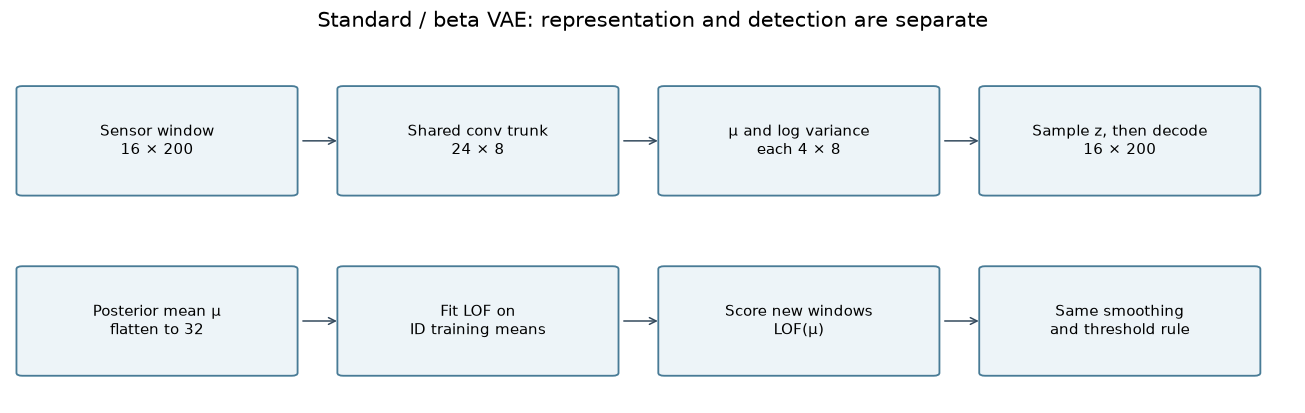

In [2]:
diagram([['Sensor window\n16 × 200','Shared conv trunk\n24 × 8','μ and log variance\neach 4 × 8','Sample z, then decode\n16 × 200'], ['Posterior mean μ\nflatten to 32','Fit LOF on\nID training means','Score new windows\nLOF(μ)','Same smoothing\nand threshold rule']], 'Standard / beta VAE: representation and detection are separate')

### Executable model and loss

The implementation is local to this notebook folder. It is not silently added to the production registry. The next pass uses random weights and dummy inputs only.

In [3]:
from _vae_experiment import ConvVAE, VAEConfig, loss_terms, train_experiment, plot_representation
model = ConvVAE()
x = torch.zeros(2, 16, 200)
rec, mu, logvar = model_shapes(model, x)
nll, kl = loss_terms(x, rec, mu, logvar)
display(pd.DataFrame({'reconstruction NLL': nll.detach().numpy(), 'KL': kl.detach().numpy()}))
assert rec.shape == x.shape and mu.shape == logvar.shape == (2, 4, 8)

ConvVAE: 30,378 parameters
Input: (2, 16, 200)   Outputs: [(2, 16, 200), (2, 4, 8), (2, 4, 8)]


,module,class,direct parameters
0,trunk.0,Conv1d,4579
1,trunk.1,BatchNorm1d,38
2,trunk.2,ReLU,0
3,trunk.3,AvgPool1d,0
4,trunk.4,Conv1d,7776
5,trunk.5,BatchNorm1d,48
6,trunk.6,ReLU,0
7,trunk.7,AvgPool1d,0
8,mu_head,Conv1d,1828
9,logvar_head,Conv1d,1828


,reconstruction NLL,KL
0,2943.182617,0.027558
1,2943.182617,0.027558


### Inspect the actual implementation

No duplicate pseudocode: this is the class and loss used by the optional trainer.

In [4]:
import inspect
print(inspect.getsource(ConvVAE))
print(inspect.getsource(loss_terms))

class ConvVAE(nn.Module):
    def __init__(self, channels=16, window=200):
        super().__init__()
        reference=ConvAutoencoder(channels,window)
        self.trunk=reference.encoder[:8]  # 16×200 -> 24×8, same first two AE blocks
        self.mu_head=nn.Conv1d(24,4,19,padding=9)
        self.logvar_head=nn.Conv1d(24,4,19,padding=9)
        self.decoder=reference.decoder

    def encode(self,x):
        h=self.trunk(x)
        return self.mu_head(h),self.logvar_head(h).clamp(-8,8)

    def forward(self,x,sample=None):
        mu,logvar=self.encode(x)
        sample=self.training if sample is None else sample
        z=mu+torch.exp(.5*logvar)*torch.randn_like(mu) if sample else mu
        return self.decoder(z),mu,logvar

def loss_terms(x,reconstruction,mu,logvar):
    """Per-window sums (NOT mean reconstruction mixed with summed KL)."""
    nll=.5*((x-reconstruction).square()+math.log(2*math.pi)).flatten(1).sum(1)
    kl=.5*(mu.square()+logvar.exp()-1-logvar).flatten(1).sum(1)
 

## What the variants test

| Variant | KL weight | Primary OOD score | Question |
|---|---:|---|---|
| Standard VAE + LOF | 1 | LOF on posterior means | Does probabilistic regularization help latent density detection? |
| β-VAE + LOF | 4 | Same LOF procedure | Does stronger regularization improve generalization or erase task distinctions? |

**Diagnostic score ablations for each model:** reconstruction NLL, KL, and negative ELBO
(reconstruction NLL + KL, regardless of training β). The latter uses eight posterior samples
per window; it is a Monte Carlo estimate of a bound, not exact negative log likelihood.
Do not call these scores calibrated OOD probabilities or choose a different winner on each test task.

## Training protocol and controls

- Default original task split; set `HELD_OUT` to `SA`, `ST`, or `TR` to use the existing LOTO builder.
- Participant-disjoint early-stopping subset inside the training pool, matching the AE approach.
  Adam LR 0.001, batch 256, ceiling 50 epochs, patience 5. These are proposed prototype settings.
- The loss samples z during both training and validation; validation uses a fixed random seed.
- LOF reference latents and the 99.5th-percentile thresholds use ID training data only.
  Evaluation uses the existing per-trial causal median filter and metric functions.
- To compare variants, keep the seed/splits fixed; repeat with seeds 0, 1, 2 before conclusions.
  For a fair new operating-point comparison, recalibrate **both** AE and VAE on the same
  validation-ID false-alarm budget. The prototype first reproduces the existing training-percentile rule.
- The optional window cap is a **smoke test**, not a benchmark. No training is run by default.

In [5]:
HELD_OUT = None  # None, 'SA', 'ST', 'TR'
SEED = 0
VARIANTS = {'standard': 1.0, 'beta4': 4.0}
protocol = HELD_OUT or 'original'
VAE_RUNS = {name: ROOT / 'notebooks/model_exploration/runs/vae' / f'{protocol}_{name}_seed{SEED}'
            for name in VARIANTS}
configs = {name: VAEConfig(beta=beta, seed=SEED, held_out=HELD_OUT)
           for name, beta in VARIANTS.items()}
display(pd.DataFrame({name: asdict(cfg) for name, cfg in configs.items()}))
for name, out in VAE_RUNS.items():
    print(name, 'existing results' if (out/'report.json').exists() else 'NOT TRAINED', out)
if RUN_TRAINING:
    for name, cfg in configs.items():
        train_experiment(VAE_RUNS[name], cfg)
else:
    print('Training disabled. Change RUN_TRAINING explicitly to create new runs.')

,standard,beta4
beta,1.000,4.000
lr,0.001,0.001
batch_size,256.000,256.000
max_epochs,50.000,50.000
patience,5.000,5.000
seed,0.000,0.000
val_fraction,0.200,0.200
held_out,NaN,NaN
device,NaN,NaN
max_train_windows,NaN,NaN


standard NOT TRAINED /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/model_exploration/runs/vae/original_standard_seed0
beta4 NOT TRAINED /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/model_exploration/runs/vae/original_beta4_seed0
Training disabled. Change RUN_TRAINING explicitly to create new runs.


## Learning curves, scores and learned representations

These cells will populate after training; they do not fill missing results with toy metrics. PCA is fitted on training reference means, then test means are projected into that fixed basis.

In [6]:
for name, out in VAE_RUNS.items():
    display(Markdown(f'### {name}: saved artifacts'))
    inventory(out)
    config_and_history(out)
    results_table(out)
    plot_representation(out)

### standard: saved artifacts

**Artifact directory:** `notebooks/model_exploration/runs/vae/original_standard_seed0`

,artifact,available
0,report.json,False
1,final.pt,False
2,eval_test.json,False
3,figures,False


No completed training report here. Architecture/commands below are not results.
No saved training history.
No saved test evaluation; no performance is inferred.
No trained VAE representation yet. Enable training above, then rerun.


### beta4: saved artifacts

**Artifact directory:** `notebooks/model_exploration/runs/vae/original_beta4_seed0`

,artifact,available
0,report.json,False
1,final.pt,False
2,eval_test.json,False
3,figures,False


No completed training report here. Architecture/commands below are not results.
No saved training history.
No saved test evaluation; no performance is inferred.
No trained VAE representation yet. Enable training above, then rerun.


## Read the experiment, not just the pictures

1. Do LOF scores improve over the existing AE at a comparable false-alarm rate, consistently across seeds?
2. Does a smaller KL reflect useful regularization or posterior collapse? Inspect both loss components.
3. Does standing receive low reconstruction NLL because it is simple? That would repeat the known AE failure.
4. Does the score identify large forecasting errors, or just task identity? These are different objectives.

Standing has only one test trial; overlapping windows cannot support a strong population-level
claim. The already-inspected test set is exploratory evidence, not a fresh confirmation set.
An attractive PCA plot, better likelihood, or a single favorable AUROC is not a go/no-go criterion.

**Continue** if there is repeatable improvement or useful complementary failure detection.
**Reconsider** if it only reconstructs better or preserves the same failure pattern without added information.

## Sources and further reading

- [Notebook-local implementation](_vae_experiment.py); [AE baseline](../../ml/vanilla/models/autoencoder.py).
- [Kingma & Welling: Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114).
- [Nalisnick et al.: generative likelihood can fail at OOD detection](https://arxiv.org/abs/1810.09136).
- [Higgins et al.: beta-VAE](https://openreview.net/forum?id=Sy2fzU9gl).

Literature findings motivate this experiment; they do not establish performance on hip-exoskeleton data.